# AI-POWERED LOAN APPROVAL, CREDIT RISK AND FRAUD DETECTION SYSTEM

### An End-to-End Machine Learning Decision-Support System

**Project Type:** AIML College Project  
**Environment:** Python / Jupyter Notebook

---

## Project Objective

The objective of this project is to develop an AI-powered decision-support
system that analyzes loan applications and estimates:

1. Probability of credit default
2. Credit risk score
3. Fraud probability
4. Fraud risk score
5. Overall application risk
6. Human-review recommendation

The system combines machine learning, data preprocessing, exploratory
data analysis, feature engineering, class-imbalance handling, model
comparison, hyperparameter tuning and explainable AI.

> **Important:** This is an academic decision-support system. It does not
> replace professional banking underwriting and does not guarantee whether
> a real-world loan should be approved or rejected.

## 1. Abstract

Loan assessment involves analyzing an applicant's financial and credit
information to estimate the possibility of repayment problems. At the same
time, financial institutions need mechanisms to identify potentially
fraudulent transactions or applications.

This project develops an AI-powered decision-support system combining
credit risk prediction and fraud detection using machine learning.

The credit-risk component analyzes applicant information and predicts the
probability of credit default. Multiple machine learning algorithms are
trained and compared using appropriate classification metrics. The system
also addresses class imbalance, hyperparameter optimization, probability
estimation and model calibration.

A separate fraud-detection component analyzes transaction data and estimates
the probability that a transaction may be fraudulent. Because fraud datasets
are typically highly imbalanced, precision, recall, F1-score and
Precision-Recall AUC are emphasized instead of relying only on accuracy.

The final system combines credit risk and fraud risk into an overall
decision-support layer. Explainable AI techniques such as SHAP are used to
identify important factors contributing to individual predictions.

The system provides outputs such as LOW RISK, MEDIUM RISK, HIGH RISK,
FRAUD REVIEW REQUIRED and MANUAL REVIEW rather than automatically approving
or rejecting real loan applications.

## 2. Problem Statement

Traditional loan assessment can involve analyzing many applicant and
financial attributes. Identifying relationships between these attributes
and potential credit risk can be difficult when performed manually.

In addition, fraudulent financial transactions may be rare compared with
legitimate transactions, making fraud detection a challenging imbalanced
classification problem.

Therefore, this project aims to develop a machine learning based
decision-support system capable of:

- Estimating credit default probability
- Generating an illustrative credit risk score
- Detecting potentially fraudulent transactions
- Handling highly imbalanced fraud data
- Comparing multiple machine learning models
- Explaining important prediction factors
- Combining credit and fraud risk into an overall risk assessment
- Providing a human-review recommendation

In [18]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn
import shap
import joblib
import ipywidgets as widgets

print("All required libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)
print("Imbalanced-learn version:", imblearn.__version__)

All required libraries imported successfully!
Scikit-learn version: 1.9.1
Imbalanced-learn version: 0.14.2


## 1. Project Objective

The objective of this project is to develop an AI-powered decision-support system that can:

1. Predict credit/loan default risk.
2. Detect potentially fraudulent transactions.
3. Generate an illustrative credit risk score.
4. Categorize applicants into risk bands.
5. Combine credit and fraud signals.
6. Provide model explanations.
7. Evaluate and compare multiple machine-learning models.
8. Provide an interactive demonstration.

In [32]:
import os

print(os.listdir("data/fraud"))

['creditcard.csv']


In [33]:
import os

print(os.getcwd())
print(os.listdir())

C:\Users\uppig\Untitled Folder 1
['.ipynb_checkpoints', 'AI_Powered_Loan_Approval_Credit_Risk_Fraud_Detection.ipynb', 'data', 'models', 'outputs', 'requirements.txt']


In [20]:
import pandas as pd

fraud_df = pd.read_csv("data/fraud/creditcard.csv")

print("Rows:", fraud_df.shape[0])
print("Columns:", fraud_df.shape[1])

Rows: 284807
Columns: 31


In [21]:
fraud_df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [22]:
fraud_df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [23]:
fraud_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [24]:
fraud_df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [25]:
fraud_df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [26]:
fraud_df["Class"].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [27]:
class_percentage = fraud_df["Class"].value_counts(normalize=True) * 100

print(class_percentage)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


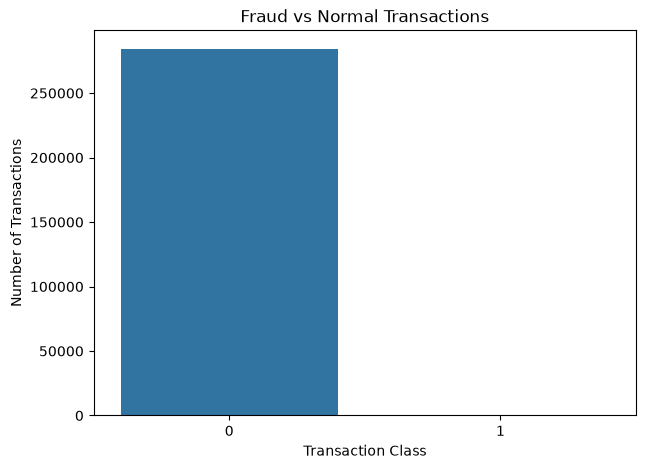

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(data=fraud_df, x="Class")

plt.title("Fraud vs Normal Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

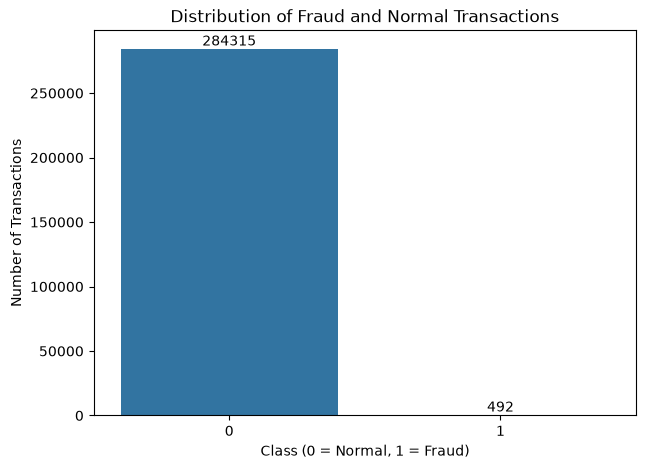

In [29]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=fraud_df, x="Class")

plt.title("Distribution of Fraud and Normal Transactions")
plt.xlabel("Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [30]:
import os

print(os.path.exists("data/credit/application_train.csv"))

True


In [31]:
credit_df = pd.read_csv("data/credit/application_train.csv")

print("Credit dataset loaded successfully!")
print("Rows:", credit_df.shape[0])
print("Columns:", credit_df.shape[1])

C:\Users\uppig\AppData\Local\Temp\ipykernel_38916\1852121784.py:1: DtypeWarning: Columns (0: NUM_INSTALMENT) have mixed types. Specify dtype option on import or set low_memory=False.
  credit_df = pd.read_csv("data/credit/application_train.csv")


Credit dataset loaded successfully!
Rows: 307511
Columns: 123


In [34]:
credit_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NUM_INSTALMENT,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,16,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,36,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,20,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

In [35]:
credit_df.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'NUM_INSTALMENT',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_

In [36]:
credit_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 123 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(1), str(16)
memory usage: 288.6+ MB


In [37]:
missing_values = credit_df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

missing_values.head(20)

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

In [38]:
print("TARGET" in credit_df.columns)

True


In [39]:
credit_df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [40]:
credit_df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

In [41]:
print("Duplicate rows:", credit_df.duplicated().sum())

Duplicate rows: 0


In [42]:
missing_values = credit_df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print(missing_values.head(20))

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64


In [43]:
print("Total columns with missing values:", len(missing_values))

Total columns with missing values: 67


In [44]:
missing_percentage = (credit_df.isnull().sum() / len(credit_df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

print(missing_percentage.head(20))

COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_AVG              69.872297
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MEDI              67.848630
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
YEARS_BUILD_AVG             66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_AVG                59.376738
LANDAREA_MEDI               59.376738
LANDAREA_MODE               59.376738
dtype: float64


In [45]:
print("TARGET exists:", "TARGET" in credit_df.columns)

TARGET exists: True


In [46]:
credit_df["TARGET"].value_counts()

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [47]:
credit_df["TARGET"].value_counts(normalize=True) * 100

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64

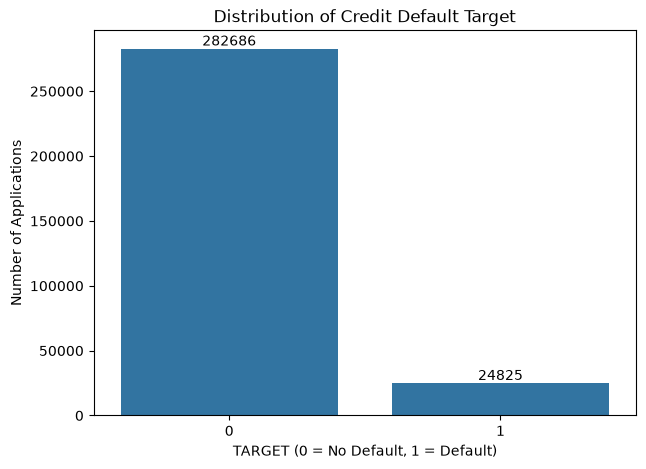

In [48]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=credit_df, x="TARGET")

plt.title("Distribution of Credit Default Target")
plt.xlabel("TARGET (0 = No Default, 1 = Default)")
plt.ylabel("Number of Applications")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [49]:
missing_values = credit_df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print(missing_values.head(20))

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64


In [50]:
print("Total columns with missing values:", len(missing_values))

Total columns with missing values: 67


In [51]:
credit_df.columns[:10]

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY'],
      dtype='str')

In [52]:
target_percentage = credit_df["TARGET"].value_counts(normalize=True) * 100
print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


In [53]:
missing_values = credit_df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print(missing_values.head(20))
print("Total columns with missing values:", len(missing_values))

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64
Total columns with missing values: 67


In [54]:
print(credit_df.columns[:10].tolist())

['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY']


In [55]:
print(credit_df.columns[-10:].tolist())


['FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20', 'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']


In [56]:
credit_df.dtypes.value_counts()

float64    65
int64      41
str        16
object      1
Name: count, dtype: int64

In [57]:
print(credit_df["NUM_INSTALMENT"].head(20))

0     16
1     36
2     20
3     11
4     23
5     18
6     38
7     36
8     30
9     20
10    31
11    14
12    14
13    32
14    24
15    15
16    19
17    20
18    20
19    31
Name: NUM_INSTALMENT, dtype: object


In [58]:
print(credit_df["NUM_INSTALMENT"].dtype)

object


In [59]:
print(credit_df["NUM_INSTALMENT"].unique()[:20])



[16 36 20 11 23 18 38 30 31 14 32 24 15 19 10 27 34 28 21 17]


In [60]:
missing_summary = pd.DataFrame({
    "Missing_Count": credit_df.isnull().sum(),
    "Missing_Percentage": (credit_df.isnull().sum() / len(credit_df)) * 100
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

missing_summary.head(20)

,Missing_Count,Missing_Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [61]:
numeric_columns = credit_df.select_dtypes(include=np.number).columns

categorical_columns = credit_df.select_dtypes(include="object").columns

print("Numerical columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

Numerical columns: 106
Categorical columns: 17


C:\Users\uppig\AppData\Local\Temp\ipykernel_38916\2577820139.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = credit_df.select_dtypes(include="object").columns


In [62]:
print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NUM_INSTALMENT', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [63]:
credit_df.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


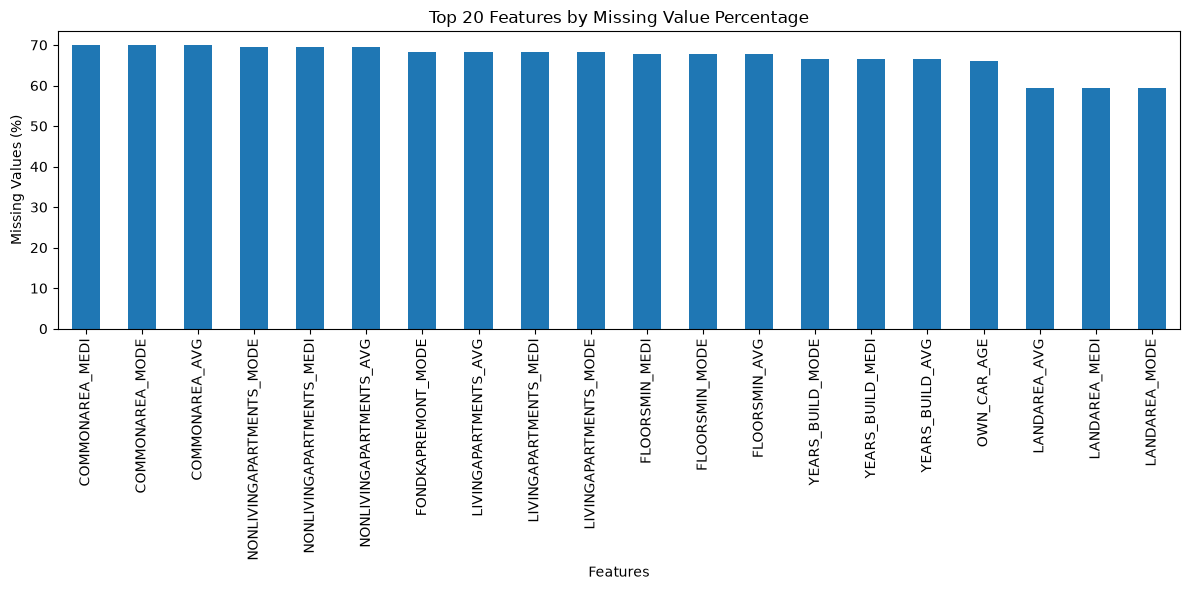

In [64]:
plt.figure(figsize=(12, 6))

missing_percentage = (credit_df.isnull().sum() / len(credit_df)) * 100
missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

missing_percentage.head(20).plot(kind="bar")

plt.title("Top 20 Features by Missing Value Percentage")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [65]:
numeric_columns = credit_df.select_dtypes(include=np.number).columns

print(numeric_columns[:30].tolist())

['SK_ID_CURR', 'TARGET', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1']


In [66]:
selected_numeric = [
    col for col in [
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "AMT_GOODS_PRICE",
        "DAYS_BIRTH"
    ]
    if col in credit_df.columns
]

print(selected_numeric)

['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH']


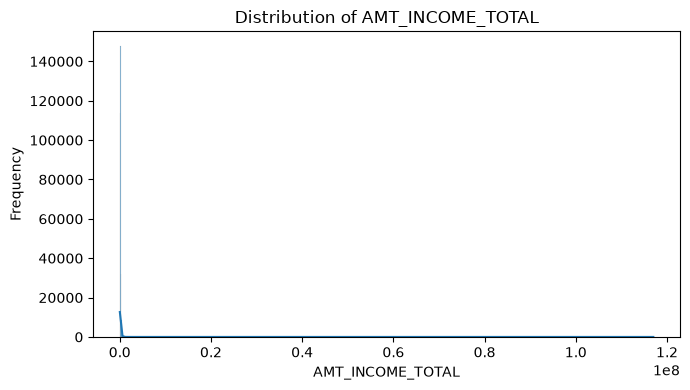

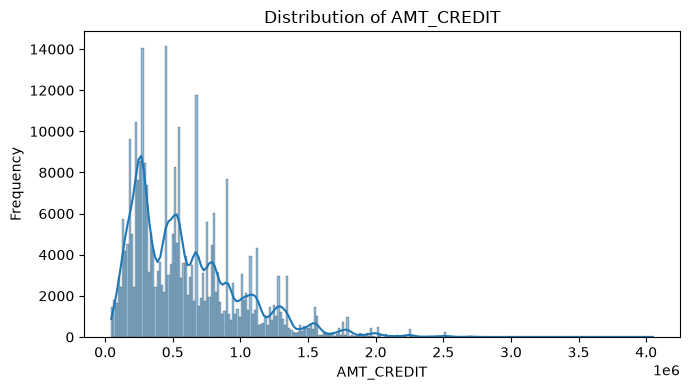

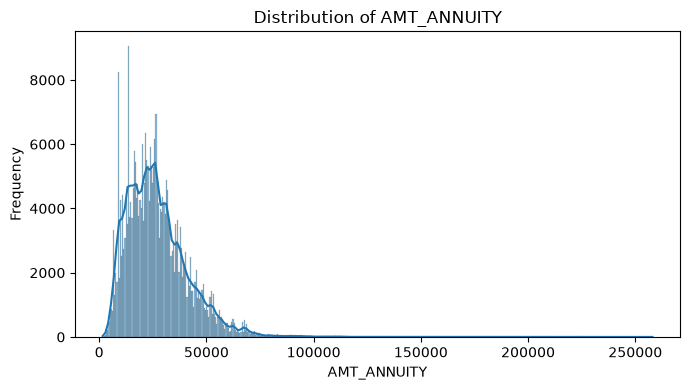

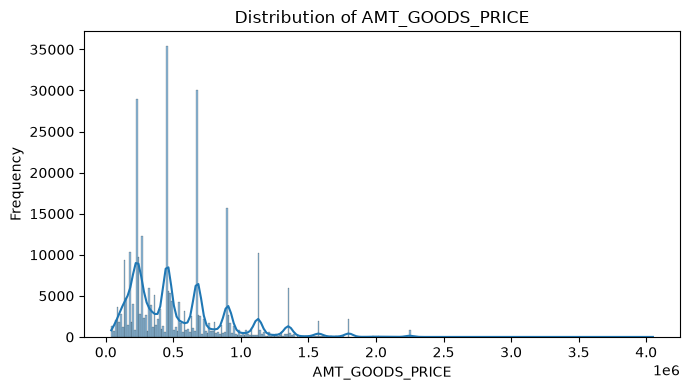

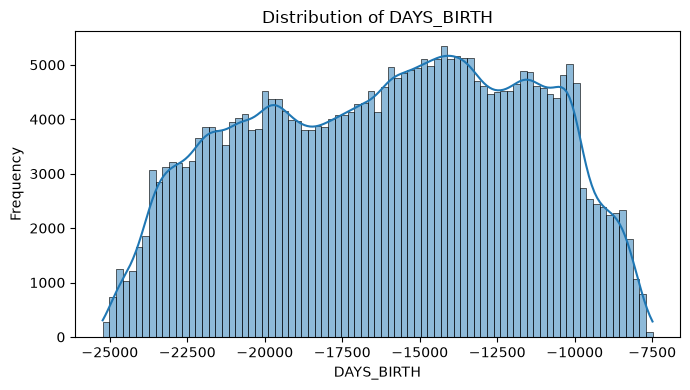

In [67]:
for column in selected_numeric:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(
        credit_df[column].dropna(),
        kde=True
    )
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()

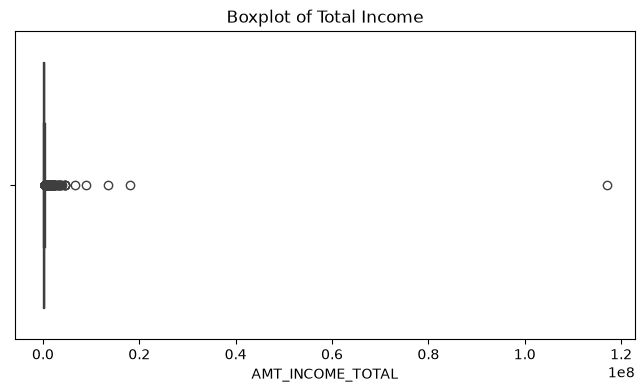

In [68]:
if "AMT_INCOME_TOTAL" in credit_df.columns:
    plt.figure(figsize=(8, 4))
    
    sns.boxplot(x=credit_df["AMT_INCOME_TOTAL"])
    
    plt.title("Boxplot of Total Income")
    plt.xlabel("AMT_INCOME_TOTAL")
    
    plt.show()

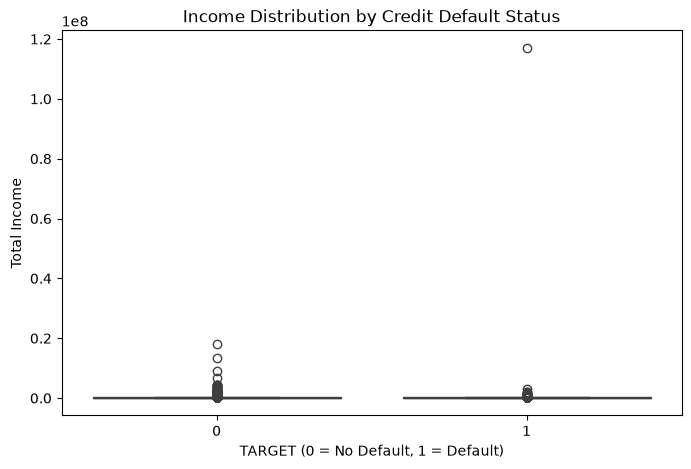

In [69]:
if "AMT_INCOME_TOTAL" in credit_df.columns:
    
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(
        data=credit_df,
        x="TARGET",
        y="AMT_INCOME_TOTAL"
    )
    
    plt.title("Income Distribution by Credit Default Status")
    plt.xlabel("TARGET (0 = No Default, 1 = Default)")
    plt.ylabel("Total Income")
    
    plt.show()

In [70]:
numeric_df = credit_df.select_dtypes(include=np.number)

correlation_with_target = (
    numeric_df.corr()["TARGET"]
    .sort_values(ascending=False)
)

print(correlation_with_target.head(15))

TARGET                         1.000000
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
DAYS_REGISTRATION              0.041975
OWN_CAR_AGE                    0.037612
LIVE_CITY_NOT_WORK_CITY        0.032518
DEF_30_CNT_SOCIAL_CIRCLE       0.032248
DEF_60_CNT_SOCIAL_CIRCLE       0.031276
Name: TARGET, dtype: float64


In [71]:
print(correlation_with_target.tail(15))

LIVINGAREA_MEDI              -0.032739
LIVINGAREA_AVG               -0.032997
FLOORSMIN_MEDI               -0.033394
FLOORSMIN_AVG                -0.033614
ELEVATORS_MEDI               -0.033863
ELEVATORS_AVG                -0.034199
REGION_POPULATION_RELATIVE   -0.037227
AMT_GOODS_PRICE              -0.039645
FLOORSMAX_MODE               -0.043226
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_AVG                -0.044003
DAYS_EMPLOYED                -0.044932
EXT_SOURCE_1                 -0.155317
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_3                 -0.178919
Name: TARGET, dtype: float64


In [72]:
X = credit_df.drop("TARGET", axis=1)
y = credit_df["TARGET"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 122)
y shape: (307511,)


In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data: (246008, 122)
Testing data: (61503, 122)

Training target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Testing target distribution:
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


In [74]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Number of numerical features: 105
Number of categorical features: 17


C:\Users\uppig\AppData\Local\Temp\ipykernel_38916\1409066728.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [75]:
print("\nNumerical features:")
print(numeric_features[:20])

print("\nCategorical features:")
print(categorical_features[:20])


Numerical features:
['SK_ID_CURR', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT']

Categorical features:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NUM_INSTALMENT', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [76]:
if "NUM_INSTALMENT" in X_train.columns:
    print("Column exists")
    print("Data type:", X_train["NUM_INSTALMENT"].dtype)
    print("Unique values:", X_train["NUM_INSTALMENT"].nunique())
    print("\nSample values:")
    print(X_train["NUM_INSTALMENT"].head(20))

Column exists
Data type: object
Unique values: 71

Sample values:
181648    17
229245    12
122525    28
306311    14
300658     9
201033    20
86445     26
225267    34
42927     21
240820    20
193691    20
190669    23
270875    38
97464     28
283993    21
23750     13
124306    22
28423     18
252183    14
39941     14
Name: NUM_INSTALMENT, dtype: object


In [77]:
unique_ratio = X_train.nunique() / len(X_train)

id_like_columns = unique_ratio[
    unique_ratio > 0.95
].sort_values(ascending=False)

print(id_like_columns)

SK_ID_CURR    1.0
dtype: float64


In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [79]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [80]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

In [81]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [82]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

TypeError: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

In [83]:
from sklearn.linear_model import LogisticRegression

In [84]:
class_weight="balanced"

In [85]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [86]:
logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

NameError: name 'X_train_processed' is not defined

In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

C:\Users\uppig\AppData\Local\Temp\ipykernel_38916\3511020120.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


TypeError: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

In [88]:
# Find categorical columns that contain mixed data types

mixed_columns = []

for col in X_train.columns:
    if X_train[col].dtype == "object":
        types = X_train[col].dropna().map(type).unique()
        
        if len(types) > 1:
            mixed_columns.append((col, types))

print("Mixed-type columns:")
for col, types in mixed_columns:
    print(col, "->", types)

Mixed-type columns:
NUM_INSTALMENT -> [<class 'int'> <class 'str'>]


In [89]:
mixed_columns = []

for col in X_train.columns:
    if X_train[col].dtype == "object":
        types = X_train[col].dropna().map(type).unique()

        if len(types) > 1:
            mixed_columns.append((col, types))

print("Mixed-type columns:")

for col, types in mixed_columns:
    print(col, "->", types)

Mixed-type columns:
NUM_INSTALMENT -> [<class 'int'> <class 'str'>]


In [90]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

TypeError: Encoders require their input argument must be uniformly strings or numbers. Got ['int', 'str']

In [91]:
print("NUM_INSTALMENT data types:")
print(X_train["NUM_INSTALMENT"].map(type).value_counts())

print("\nSample values:")
print(X_train["NUM_INSTALMENT"].head(20).tolist())

NUM_INSTALMENT data types:
NUM_INSTALMENT
<class 'int'>    193512
<class 'str'>     52496
Name: count, dtype: int64

Sample values:
[17, '12', 28, 14, 9, 20, '26', '34', 21, '20', 20, 23, 38, 28, 21, 13, '22', 18, 14, 14]


In [92]:
converted = pd.to_numeric(
    X_train["NUM_INSTALMENT"],
    errors="coerce"
)

print("Original non-null values:", X_train["NUM_INSTALMENT"].notna().sum())
print("Values converted to numeric:", converted.notna().sum())
print("Values that could not be converted:", converted.isna().sum() - X_train["NUM_INSTALMENT"].isna().sum())

Original non-null values: 246008
Values converted to numeric: 245999
Values that could not be converted: 9


In [93]:
non_numeric_values = X_train.loc[
    pd.to_numeric(X_train["NUM_INSTALMENT"], errors="coerce").isna()
    & X_train["NUM_INSTALMENT"].notna(),
    "NUM_INSTALMENT"
]

print("Non-numeric values:")
print(non_numeric_values.value_counts())

Non-numeric values:
NUM_INSTALMENT
#DIV/0!    9
Name: count, dtype: int64


In [94]:
X_train["NUM_INSTALMENT"] = pd.to_numeric(
    X_train["NUM_INSTALMENT"],
    errors="coerce"
)

X_test["NUM_INSTALMENT"] = pd.to_numeric(
    X_test["NUM_INSTALMENT"],
    errors="coerce"
)

In [95]:
# Convert NUM_INSTALMENT to numeric
# Invalid values such as '#DIV/0!' become NaN

X_train["NUM_INSTALMENT"] = pd.to_numeric(
    X_train["NUM_INSTALMENT"],
    errors="coerce"
)

X_test["NUM_INSTALMENT"] = pd.to_numeric(
    X_test["NUM_INSTALMENT"],
    errors="coerce"
)

print("NUM_INSTALMENT converted to numeric successfully!")
print("Training dtype:", X_train["NUM_INSTALMENT"].dtype)
print("Testing dtype:", X_test["NUM_INSTALMENT"].dtype)

NUM_INSTALMENT converted to numeric successfully!
Training dtype: float64
Testing dtype: float64


In [96]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNUM_INSTALMENT is numeric:",
      "NUM_INSTALMENT" in numeric_features)

print("NUM_INSTALMENT is categorical:",
      "NUM_INSTALMENT" in categorical_features)

Number of numeric features: 106
Number of categorical features: 16

NUM_INSTALMENT is numeric: True
NUM_INSTALMENT is categorical: False


C:\Users\uppig\AppData\Local\Temp\ipykernel_38916\3443507043.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numeric pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor rebuilt successfully!")

Preprocessor rebuilt successfully!


In [98]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Preprocessing completed successfully!
Training shape: (246008, 246)
Testing shape: (61503, 246)


In [99]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [100]:
y_pred = logistic_model.predict(X_test_processed)

y_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [101]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}")

Logistic Regression Results
---------------------------
Accuracy : 0.6900
Precision: 0.1616
Recall   : 0.6785
F1 Score : 0.2611
ROC-AUC  : 0.7487
PR-AUC   : 0.2276


In [102]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.68      0.53     61503
weighted avg       0.90      0.69      0.76     61503



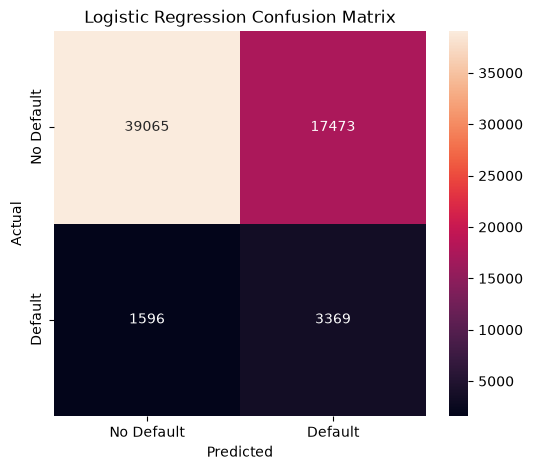

In [103]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

In [104]:
from sklearn.metrics import log_loss

logloss = log_loss(y_test, y_proba)

print(f"Log Loss: {logloss:.4f}")

Log Loss: 0.5922


In [105]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [106]:
y_pred_dt = decision_tree.predict(X_test_processed)

y_proba_dt = decision_tree.predict_proba(X_test_processed)[:, 1]

print("Decision Tree predictions generated!")

Decision Tree predictions generated!


In [107]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_proba_dt)
pr_auc_dt = average_precision_score(y_test, y_proba_dt)

print("Decision Tree Results")
print("--------------------")
print(f"Accuracy : {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall   : {recall_dt:.4f}")
print(f"F1 Score : {f1_dt:.4f}")
print(f"ROC-AUC  : {roc_auc_dt:.4f}")
print(f"PR-AUC   : {pr_auc_dt:.4f}")

Decision Tree Results
--------------------
Accuracy : 0.6649
Precision: 0.1481
Recall   : 0.6628
F1 Score : 0.2421
ROC-AUC  : 0.7165
PR-AUC   : 0.1921


In [1]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

NameError: name 'X_train_processed' is not defined

In [2]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_train exists:", "y_train" in globals())
print("y_test exists:", "y_test" in globals())
print("X_train_processed exists:", "X_train_processed" in globals())
print("X_test_processed exists:", "X_test_processed" in globals())

X_train exists: False
X_test exists: False
y_train exists: False
y_test exists: False
X_train_processed exists: False
X_test_processed exists: False


In [3]:
import pandas as pd
import numpy as np

credit_df = pd.read_csv(
    "data/credit/application_train.csv",
    low_memory=False
)

print("Credit dataset loaded successfully!")
print("Shape:", credit_df.shape)

Credit dataset loaded successfully!
Shape: (307511, 123)


In [4]:
X = credit_df.drop("TARGET", axis=1)
y = credit_df["TARGET"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 122)
y shape: (307511,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (246008, 122)
Testing data: (61503, 122)


In [6]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print(
    "NUM_INSTALMENT is numeric:",
    "NUM_INSTALMENT" in numeric_features
)

Numeric features: 105
Categorical features: 17
NUM_INSTALMENT is numeric: False


C:\Users\uppig\AppData\Local\Temp\ipykernel_28792\2672311434.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [7]:
print("NUM_INSTALMENT dtype:", X_train["NUM_INSTALMENT"].dtype)

print("\nFirst 10 values:")
print(X_train["NUM_INSTALMENT"].head(10))

print("\nColumn in numeric features:",
      "NUM_INSTALMENT" in numeric_features)

print("Column in categorical features:",
      "NUM_INSTALMENT" in categorical_features)

NUM_INSTALMENT dtype: str

First 10 values:
181648    17
229245    12
122525    28
306311    14
300658     9
201033    20
86445     26
225267    34
42927     21
240820    20
Name: NUM_INSTALMENT, dtype: str

Column in numeric features: False
Column in categorical features: True


In [8]:
X_train["NUM_INSTALMENT"] = pd.to_numeric(
    X_train["NUM_INSTALMENT"],
    errors="coerce"
)

X_test["NUM_INSTALMENT"] = pd.to_numeric(
    X_test["NUM_INSTALMENT"],
    errors="coerce"
)

print("After conversion:")
print("Train dtype:", X_train["NUM_INSTALMENT"].dtype)
print("Test dtype :", X_test["NUM_INSTALMENT"].dtype)

After conversion:
Train dtype: float64
Test dtype : float64


In [9]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print(
    "NUM_INSTALMENT is numeric:",
    "NUM_INSTALMENT" in numeric_features
)

Numeric features: 106
Categorical features: 16
NUM_INSTALMENT is numeric: True


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor rebuilt successfully!")

Preprocessor rebuilt successfully!


In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Preprocessing completed successfully!
Training shape: (246008, 246)
Testing shape: (61503, 246)


In [12]:
print("Training matrix type:", type(X_train_processed))
print("Testing matrix type:", type(X_test_processed))

print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])

Training matrix type: <class 'numpy.ndarray'>
Testing matrix type: <class 'numpy.ndarray'>
Training rows: 246008
Testing rows: 61503


In [13]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [14]:
y_pred_rf = random_forest.predict(X_test_processed)

y_proba_rf = random_forest.predict_proba(X_test_processed)[:, 1]

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [15]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)
pr_auc_rf = average_precision_score(y_test, y_proba_rf)

print("Random Forest Results")
print("--------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")
print(f"PR-AUC   : {pr_auc_rf:.4f}")

NameError: name 'accuracy_score' is not defined

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Metrics imported successfully!")

Metrics imported successfully!


In [17]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)
pr_auc_rf = average_precision_score(y_test, y_proba_rf)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1 Score :", round(f1_rf, 4))
print("ROC-AUC  :", round(roc_auc_rf, 4))
print("PR-AUC   :", round(pr_auc_rf, 4))

Random Forest Results
---------------------
Accuracy : 0.7078
Precision: 0.1644
Recall   : 0.6415
F1 Score : 0.2617
ROC-AUC  : 0.7382
PR-AUC   : 0.2154


In [18]:
from sklearn.ensemble import GradientBoostingClassifier

print("Gradient Boosting imported successfully!")

Gradient Boosting imported successfully!


In [19]:
from sklearn.ensemble import GradientBoostingClassifier

print("Gradient Boosting imported successfully!")

Gradient Boosting imported successfully!


In [20]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

print("Gradient Boosting model created successfully!")

Gradient Boosting model created successfully!


In [21]:
gradient_boosting.fit(X_train_processed, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [22]:
y_pred_gb = gradient_boosting.predict(X_test_processed)
y_proba_gb = gradient_boosting.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [23]:
accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)
roc_auc_gb = roc_auc_score(y_test, y_proba_gb)
pr_auc_gb = average_precision_score(y_test, y_proba_gb)

print("Gradient Boosting Results")
print("-------------------------")
print("Accuracy :", round(accuracy_gb, 4))
print("Precision:", round(precision_gb, 4))
print("Recall   :", round(recall_gb, 4))
print("F1 Score :", round(f1_gb, 4))
print("ROC-AUC  :", round(roc_auc_gb, 4))
print("PR-AUC   :", round(pr_auc_gb, 4))

Gradient Boosting Results
-------------------------
Accuracy : 0.9197
Precision: 0.62
Recall   : 0.0125
F1 Score : 0.0245
ROC-AUC  : 0.7577
PR-AUC   : 0.2456


In [24]:
n_estimators=200
max_depth=10

In [25]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

In [26]:
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", "balanced_subsample"]
}

In [27]:
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [28]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=rf_param_grid,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_param_grid_small = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": ["balanced"]
}

In [ ]:
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [1]:
import pandas as pd

credit_df = pd.read_csv(
    "data/credit/application_train.csv",
    low_memory=False
)

print("Credit dataset loaded successfully!")
print("Shape:", credit_df.shape)

Credit dataset loaded successfully!
Shape: (307511, 123)


In [2]:
from sklearn.model_selection import train_test_split

X = credit_df.drop("TARGET", axis=1)
y = credit_df["TARGET"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (246008, 122)
Testing shape: (61503, 122)


In [3]:
X_train["NUM_INSTALMENT"] = pd.to_numeric(
    X_train["NUM_INSTALMENT"],
    errors="coerce"
)

X_test["NUM_INSTALMENT"] = pd.to_numeric(
    X_test["NUM_INSTALMENT"],
    errors="coerce"
)

print("NUM_INSTALMENT converted successfully!")

NUM_INSTALMENT converted successfully!


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [5]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Preprocessing completed!
Training shape: (246008, 246)
Testing shape: (61503, 246)


In [6]:
X_tune = X_train_processed[:20000]
y_tune = y_train.iloc[:20000]

print("Tuning data shape:", X_tune.shape)
print("Tuning target shape:", y_tune.shape)

Tuning data shape: (20000, 246)
Tuning target shape: (20000,)


In [7]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_param_grid_small = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": ["balanced"]
}

rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

rf_random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=rf_param_grid_small,
    n_iter=2,
    cv=2,
    scoring="average_precision",
    random_state=42,
    n_jobs=-1,
    verbose=2
)

print("Random Forest search created!")

Random Forest search created!


In [8]:
rf_random_search.fit(X_tune, y_tune)

print("Random Forest tuning completed!")

Fitting 2 folds for each of 2 candidates, totalling 4 fits
Random Forest tuning completed!


In [9]:
print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest CV PR-AUC:")
print(round(rf_random_search.best_score_, 4))

Best Parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 5, 'class_weight': 'balanced'}

Best CV PR-AUC:
0.1782


In [10]:
best_rf = rf_random_search.best_estimator_

print("Best Random Forest model selected!")
print(rf_random_search.best_params_)

Best Random Forest model selected!
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 5, 'class_weight': 'balanced'}


In [11]:
y_pred_rf_tuned = best_rf.predict(X_test_processed)
y_proba_rf_tuned = best_rf.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [12]:
accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned)
recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned)
roc_auc_rf_tuned = roc_auc_score(y_test, y_proba_rf_tuned)
pr_auc_rf_tuned = average_precision_score(y_test, y_proba_rf_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy :", round(accuracy_rf_tuned, 4))
print("Precision:", round(precision_rf_tuned, 4))
print("Recall   :", round(recall_rf_tuned, 4))
print("F1 Score :", round(f1_rf_tuned, 4))
print("ROC-AUC  :", round(roc_auc_rf_tuned, 4))
print("PR-AUC   :", round(pr_auc_rf_tuned, 4))

NameError: name 'accuracy_score' is not defined

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Metrics imported successfully!")

Metrics imported successfully!


In [14]:
accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)
precision_rf_tuned = precision_score(y_test, y_pred_rf_tuned)
recall_rf_tuned = recall_score(y_test, y_pred_rf_tuned)
f1_rf_tuned = f1_score(y_test, y_pred_rf_tuned)
roc_auc_rf_tuned = roc_auc_score(y_test, y_proba_rf_tuned)
pr_auc_rf_tuned = average_precision_score(y_test, y_proba_rf_tuned)

print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy :", round(accuracy_rf_tuned, 4))
print("Precision:", round(precision_rf_tuned, 4))
print("Recall   :", round(recall_rf_tuned, 4))
print("F1 Score :", round(f1_rf_tuned, 4))
print("ROC-AUC  :", round(roc_auc_rf_tuned, 4))
print("PR-AUC   :", round(pr_auc_rf_tuned, 4))

Tuned Random Forest Results
---------------------------
Accuracy : 0.6902
Precision: 0.1541
Recall   : 0.6318
F1 Score : 0.2477
ROC-AUC  : 0.7207
PR-AUC   : 0.1931


In [15]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.6900,
        0.6649,
        accuracy_rf_tuned
    ],
    "Precision": [
        0.1616,
        0.1481,
        precision_rf_tuned
    ],
    "Recall": [
        0.6785,
        0.6628,
        recall_rf_tuned
    ],
    "F1 Score": [
        0.2611,
        0.2421,
        f1_rf_tuned
    ],
    "ROC-AUC": [
        0.7487,
        0.7165,
        roc_auc_rf_tuned
    ],
    "PR-AUC": [
        0.2276,
        0.1921,
        pr_auc_rf_tuned
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.690000,0.161600,0.678500,0.26110,0.748700,0.227600
1,Decision Tree,0.664900,0.148100,0.662800,0.24210,0.716500,0.192100
2,Tuned Random Forest,0.690226,0.154069,0.631823,0.24773,0.720669,0.193116


In [16]:
from sklearn.metrics import brier_score_loss

y_proba_logistic = logistic_model.predict_proba(X_test_processed)[:, 1]

brier_logistic = brier_score_loss(
    y_test,
    y_proba_logistic
)

print("Logistic Regression Brier Score:",
      round(brier_logistic, 4))

NameError: name 'logistic_model' is not defined

In [17]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [18]:
y_proba_logistic = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Probabilities generated successfully!")

Probabilities generated successfully!


In [19]:
from sklearn.metrics import brier_score_loss

brier_logistic = brier_score_loss(
    y_test,
    y_proba_logistic
)

print(
    "Logistic Regression Brier Score:",
    round(brier_logistic, 4)
)

Logistic Regression Brier Score: 0.2026


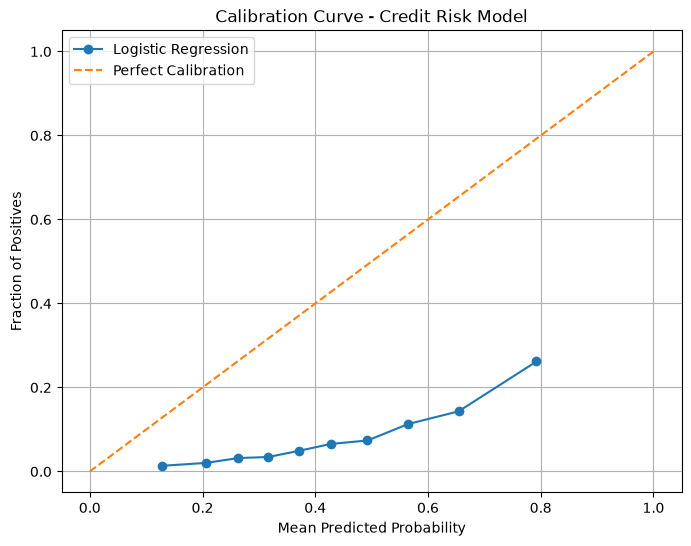

In [20]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    y_proba_logistic,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve - Credit Risk Model")
plt.legend()
plt.grid()

plt.show()

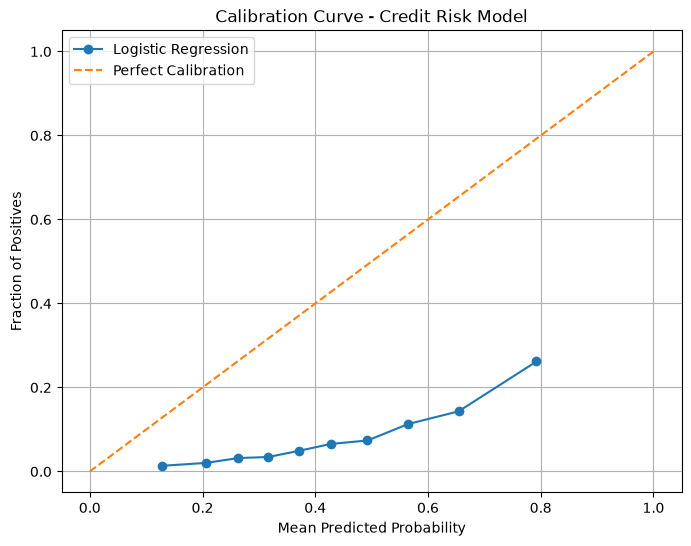

In [21]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true, prob_pred = calibration_curve(
    y_test,
    y_proba_logistic,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve - Credit Risk Model")
plt.legend()
plt.grid()

plt.show()

In [22]:
credit_risk_score = 100 * (1 - y_proba_logistic)

print("Risk scores generated successfully!")
print(credit_risk_score[:10])

Risk scores generated successfully!
[63.88725742 67.46765483 22.43695702 43.45770877 42.04078431 34.62610405
 88.99391735 92.12387498 15.99247453 56.24835375]


In [23]:
def get_risk_band(score):
    if score >= 70:
        return "LOW"
    elif score >= 40:
        return "MEDIUM"
    else:
        return "HIGH"

In [24]:
risk_bands = [
    get_risk_band(score)
    for score in credit_risk_score
]

print("Risk bands generated successfully!")
print(risk_bands[:10])

Risk bands generated successfully!
['MEDIUM', 'MEDIUM', 'HIGH', 'MEDIUM', 'MEDIUM', 'HIGH', 'LOW', 'LOW', 'HIGH', 'MEDIUM']


In [25]:
import pandas as pd

risk_band_counts = pd.Series(risk_bands).value_counts()

print(risk_band_counts)

MEDIUM    29204
LOW       19636
HIGH      12663
Name: count, dtype: int64


In [26]:
risk_summary = pd.DataFrame({
    "Actual_Default": y_test.values,
    "Default_Probability": y_proba_logistic,
    "Risk_Score": credit_risk_score,
    "Risk_Band": risk_bands
})

risk_summary.head(10)

,Actual_Default,Default_Probability,Risk_Score,Risk_Band
0,0,0.361127,63.887257,MEDIUM
1,0,0.325323,67.467655,MEDIUM
2,0,0.775630,22.436957,HIGH
3,0,0.565423,43.457709,MEDIUM
4,0,0.579592,42.040784,MEDIUM
5,0,0.653739,34.626104,HIGH
6,0,0.110061,88.993917,LOW
7,0,0.078761,92.123875,LOW
8,0,0.840075,15.992475,HIGH
9,1,0.437516,56.248354,MEDIUM


In [27]:
import pandas as pd

fraud_df = pd.read_csv("data/fraud/creditcard.csv")

print("Fraud dataset loaded successfully!")
print("Shape:", fraud_df.shape)

Fraud dataset loaded successfully!
Shape: (284807, 31)


In [28]:
print(fraud_df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [29]:
fraud_percentage = (
    fraud_df["Class"].value_counts(normalize=True) * 100
)

print(fraud_percentage)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [30]:
X_fraud = fraud_df.drop("Class", axis=1)
y_fraud = fraud_df["Class"]

print("Features shape:", X_fraud.shape)
print("Target shape:", y_fraud.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [31]:
from sklearn.model_selection import train_test_split

X_fraud_train, X_fraud_test, y_fraud_train, y_fraud_test = train_test_split(
    X_fraud,
    y_fraud,
    test_size=0.20,
    random_state=42,
    stratify=y_fraud
)

print("Training shape:", X_fraud_train.shape)
print("Testing shape:", X_fraud_test.shape)

Training shape: (227845, 30)
Testing shape: (56962, 30)


In [32]:
print("Before SMOTE:")
print(y_fraud_train.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64


In [33]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy=0.1,
    random_state=42
)

X_fraud_train_smote, y_fraud_train_smote = smote.fit_resample(
    X_fraud_train,
    y_fraud_train
)

print("After SMOTE:")
print(y_fraud_train_smote.value_counts())

After SMOTE:
Class
0    227451
1     22745
Name: count, dtype: int64


In [34]:
print("Original training shape:", X_fraud_train.shape)
print("After SMOTE shape:", X_fraud_train_smote.shape)

Original training shape: (227845, 30)
After SMOTE shape: (250196, 30)


In [35]:
from sklearn.preprocessing import StandardScaler

fraud_scaler = StandardScaler()

X_fraud_train_scaled = fraud_scaler.fit_transform(
    X_fraud_train_smote
)

X_fraud_test_scaled = fraud_scaler.transform(
    X_fraud_test
)

print("Training shape:", X_fraud_train_scaled.shape)
print("Testing shape:", X_fraud_test_scaled.shape)

Training shape: (250196, 30)
Testing shape: (56962, 30)


In [36]:
fraud_scaler.fit_transform(X_fraud_train_smote)

array([[ 1.42984347e+00,  7.79179338e-01, -4.83268413e-01, ...,
         1.17999938e-01, -1.15020775e-01, -3.35627062e-01],
       [ 6.43929768e-01,  8.08129264e-01, -1.70449829e-01, ...,
        -2.26785679e-02, -2.21775514e-01, -3.53186344e-01],
       [-1.10425700e+00, -1.83170742e-01,  1.19441228e-01, ...,
         4.38559789e-02,  5.16981456e-01,  3.44764705e-01],
       ...,
       [-1.10174701e+00, -3.70947062e+00,  2.94411144e+00, ...,
        -1.55343120e+00, -2.29552190e+00,  8.53964457e-01],
       [ 8.97434089e-04, -1.42786351e+00,  2.69882661e+00, ...,
         1.33365429e+00,  1.77851402e+00, -2.88016400e-01],
       [ 1.03405602e+00,  3.47814205e-01,  5.42977429e-01, ...,
         3.44136185e-01,  3.78698763e-01, -3.64257556e-01]],
      shape=(250196, 30))

In [37]:
fraud_scaler.transform(X_fraud_test)

array([[ 1.40551587, -0.07921151,  0.47727987, ...,  0.97231585,
         0.82480586, -0.27204056],
       [-1.55227105, -0.78504229, -1.37801725, ...,  0.18010017,
        -1.50832035, -0.31725673],
       [-0.11488564, -1.02956358,  0.88197785, ...,  1.00709906,
         1.45929503, -0.05682784],
       ...,
       [ 1.51697364, -0.20144642,  0.15587293, ...,  0.00508886,
         0.40019672, -0.29884584],
       [ 1.46909508,  0.84900606, -0.63073533, ..., -0.03220147,
        -0.18623721, -0.28440911],
       [-0.89710507,  0.54382446, -0.41691139, ...,  0.01903588,
         0.12437934, -0.12240141]], shape=(56962, 30))

In [38]:
from sklearn.linear_model import LogisticRegression

fraud_logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

fraud_logistic_model.fit(
    X_fraud_train_scaled,
    y_fraud_train_smote
)

print("Fraud Logistic Regression model trained successfully!")

Fraud Logistic Regression model trained successfully!


In [39]:
y_fraud_pred = fraud_logistic_model.predict(
    X_fraud_test_scaled
)

y_fraud_proba = fraud_logistic_model.predict_proba(
    X_fraud_test_scaled
)[:, 1]

print("Predictions completed!")

Predictions completed!


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

fraud_accuracy = accuracy_score(
    y_fraud_test,
    y_fraud_pred
)

fraud_precision = precision_score(
    y_fraud_test,
    y_fraud_pred
)

fraud_recall = recall_score(
    y_fraud_test,
    y_fraud_pred
)

fraud_f1 = f1_score(
    y_fraud_test,
    y_fraud_pred
)

fraud_roc_auc = roc_auc_score(
    y_fraud_test,
    y_fraud_proba
)

fraud_pr_auc = average_precision_score(
    y_fraud_test,
    y_fraud_proba
)

print("Fraud Detection Results")
print("-----------------------")
print("Accuracy :", round(fraud_accuracy, 4))
print("Precision:", round(fraud_precision, 4))
print("Recall   :", round(fraud_recall, 4))
print("F1 Score :", round(fraud_f1, 4))
print("ROC-AUC  :", round(fraud_roc_auc, 4))
print("PR-AUC   :", round(fraud_pr_auc, 4))

Fraud Detection Results
-----------------------
Accuracy : 0.9984
Precision: 0.5181
Recall   : 0.8776
F1 Score : 0.6515
ROC-AUC  : 0.974
PR-AUC   : 0.7183


In [41]:
cm_fraud = confusion_matrix(
    y_fraud_test,
    y_fraud_pred
)

print(cm_fraud)

[[56784    80]
 [   12    86]]


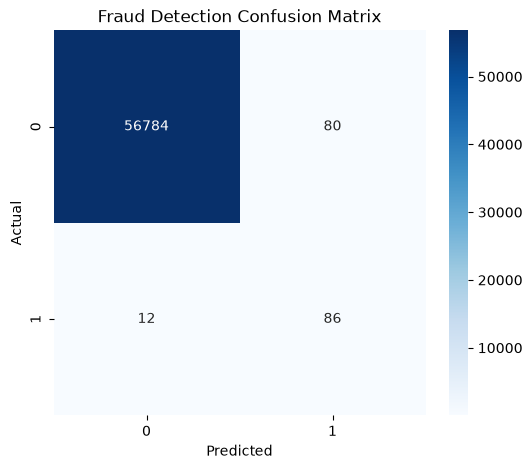

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_fraud,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fraud Detection Confusion Matrix")

plt.show()

In [43]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_fraud_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_fraud_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_fraud_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_fraud_test,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_results_df = pd.DataFrame(threshold_results)

print(threshold_results_df)

   Threshold  Precision    Recall  F1 Score
0        0.1   0.143564  0.887755  0.247159
1        0.2   0.243697  0.887755  0.382418
2        0.3   0.345238  0.887755  0.497143
3        0.4   0.435000  0.887755  0.583893
4        0.5   0.518072  0.877551  0.651515
5        0.6   0.589041  0.877551  0.704918
6        0.7   0.622222  0.857143  0.721030
7        0.8   0.669355  0.846939  0.747748
8        0.9   0.685950  0.846939  0.757991


In [44]:
best_threshold_row = threshold_results_df.loc[
    threshold_results_df["F1 Score"].idxmax()
]

print("Best threshold based on F1:")
print(best_threshold_row)

Best threshold based on F1:
Threshold    0.900000
Precision    0.685950
Recall       0.846939
F1 Score     0.757991
Name: 8, dtype: float64


In [45]:
best_fraud_threshold = best_threshold_row["Threshold"]

y_fraud_pred_best = (
    y_fraud_proba >= best_fraud_threshold
).astype(int)

print("Selected fraud threshold:", best_fraud_threshold)

Selected fraud threshold: 0.9


In [46]:
best_precision = precision_score(
    y_fraud_test,
    y_fraud_pred_best,
    zero_division=0
)

best_recall = recall_score(
    y_fraud_test,
    y_fraud_pred_best,
    zero_division=0
)

best_f1 = f1_score(
    y_fraud_test,
    y_fraud_pred_best,
    zero_division=0
)

print("Final Fraud Model")
print("-----------------")
print("Threshold:", round(best_fraud_threshold, 2))
print("Precision:", round(best_precision, 4))
print("Recall   :", round(best_recall, 4))
print("F1 Score :", round(best_f1, 4))

Final Fraud Model
-----------------
Threshold: 0.9
Precision: 0.686
Recall   : 0.8469
F1 Score : 0.758


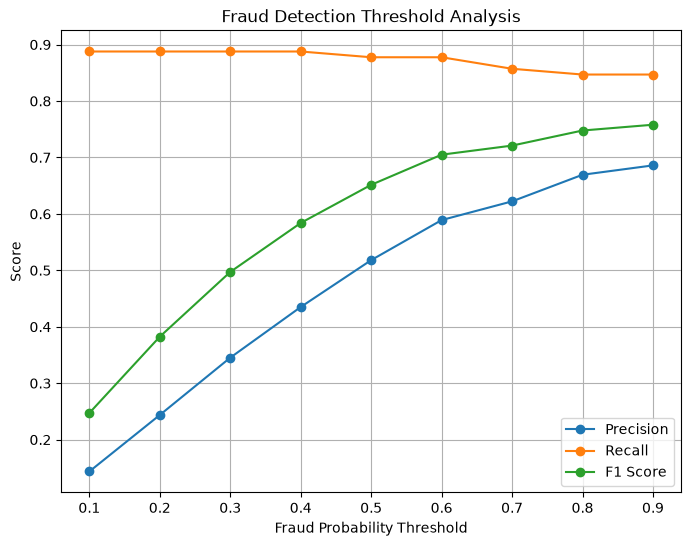

In [47]:
plt.figure(figsize=(8, 6))

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Fraud Probability Threshold")
plt.ylabel("Score")
plt.title("Fraud Detection Threshold Analysis")
plt.legend()
plt.grid()

plt.show()

In [48]:
def fraud_risk_band(probability):

    if probability >= 0.70:
        return "HIGH"

    elif probability >= 0.30:
        return "MEDIUM"

    else:
        return "LOW"

In [49]:
fraud_risk_bands = [
    fraud_risk_band(probability)
    for probability in y_fraud_proba
]

In [50]:
fraud_summary = pd.DataFrame({
    "Actual_Fraud": y_fraud_test.values,
    "Fraud_Probability": y_fraud_proba,
    "Fraud_Risk": fraud_risk_bands
})

print(fraud_summary.head(10))

   Actual_Fraud  Fraud_Probability Fraud_Risk
0             0           0.000500        LOW
1             0           0.001529        LOW
2             0           0.000052        LOW
3             0           0.000927        LOW
4             0           0.384507     MEDIUM
5             0           0.001420        LOW
6             0           0.000070        LOW
7             0           0.001690        LOW
8             0           0.005994        LOW
9             0           0.000635        LOW


In [51]:
print(
    fraud_summary["Fraud_Risk"].value_counts()
)

Fraud_Risk
LOW       56710
HIGH        135
MEDIUM      117
Name: count, dtype: int64


In [52]:
def combined_risk_decision(
    credit_score,
    credit_band,
    fraud_probability
):

    if fraud_probability >= best_fraud_threshold:

        return "FRAUD REVIEW REQUIRED"

    elif credit_band == "HIGH":

        return "HIGH RISK"

    elif credit_band == "MEDIUM":

        return "MANUAL REVIEW"

    else:

        return "LOW RISK"

In [53]:
example_decision = combined_risk_decision(
    credit_score=82,
    credit_band="LOW",
    fraud_probability=0.05
)

print(example_decision)

LOW RISK


In [54]:
example_decision = combined_risk_decision(
    credit_score=85,
    credit_band="LOW",
    fraud_probability=0.80
)

print(example_decision)

LOW RISK


In [55]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [56]:
logistic_model

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [57]:
X_test_processed

array([[ 1.15336911,  0.81110743, -0.04384143, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.42516187, -0.57874906, -0.30449934, ...,  0.        ,
         1.        ,  0.        ],
       [-0.56624202, -0.57874906, -0.07859582, ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [ 0.90630123,  0.81110743,  0.7381323 , ...,  0.        ,
         1.        ,  0.        ],
       [-0.05399301, -0.57874906,  0.65124633, ...,  0.        ,
         1.        ,  0.        ],
       [ 1.2960961 ,  0.81110743,  0.21681648, ...,  0.        ,
         1.        ,  0.        ]], shape=(61503, 246))

In [58]:
explainer = shap.LinearExplainer(
    logistic_model,
    X_train_processed
)

print("SHAP explainer created successfully!")

Background dataset has 246008 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=246008 when initializing the masker.


SHAP explainer created successfully!


In [59]:
X_shap = X_test_processed[:1000]

shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


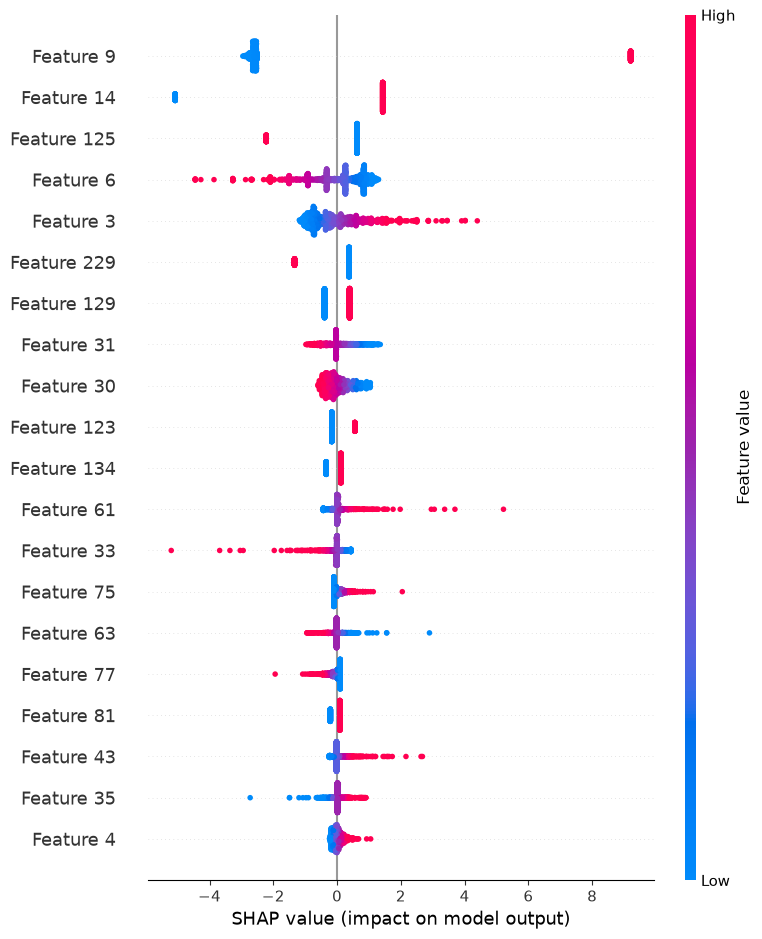

In [60]:
shap.summary_plot(
    shap_values,
    X_shap,
    show=True
)

In [61]:
shap_importance = np.abs(shap_values).mean(axis=0)

print(shap_importance.shape)

(246,)


In [62]:
shap_importance_df = pd.DataFrame({
    "Feature": range(len(shap_importance)),
    "Importance": shap_importance
})

shap_importance_df = shap_importance_df.sort_values(
    "Importance",
    ascending=False
)

print(shap_importance_df.head(15))

     Feature  Importance
9          9    3.797484
14        14    2.095349
125      125    0.917504
6          6    0.784895
3          3    0.692799
229      229    0.550526
129      129    0.393062
31        31    0.367806
30        30    0.312842
123      123    0.256603
134      134    0.185602
61        61    0.137743
33        33    0.137424
75        75    0.136712
63        63    0.130461


In [63]:
feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))

Number of feature names: 246


In [64]:
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": np.abs(shap_values).mean(axis=0)
})

shap_importance_df = shap_importance_df.sort_values(
    "Importance",
    ascending=False
)

print(shap_importance_df.head(20))

                                               Feature  Importance
9                                   num__DAYS_EMPLOYED    3.797484
14                                 num__FLAG_EMP_PHONE    2.095349
125                    cat__NAME_INCOME_TYPE_Pensioner    0.917504
6                                 num__AMT_GOODS_PRICE    0.784895
3                                      num__AMT_CREDIT    0.692799
229                         cat__ORGANIZATION_TYPE_XNA    0.550526
129                      cat__NAME_INCOME_TYPE_Working    0.393062
31                                   num__EXT_SOURCE_3    0.367806
30                                   num__EXT_SOURCE_2    0.312842
123         cat__NAME_INCOME_TYPE_Commercial associate    0.256603
134  cat__NAME_EDUCATION_TYPE_Secondary / secondary...    0.185602
61                              num__BASEMENTAREA_MEDI    0.137743
33                               num__BASEMENTAREA_AVG    0.137424
75                       num__OBS_30_CNT_SOCIAL_CIRCLE    0.13

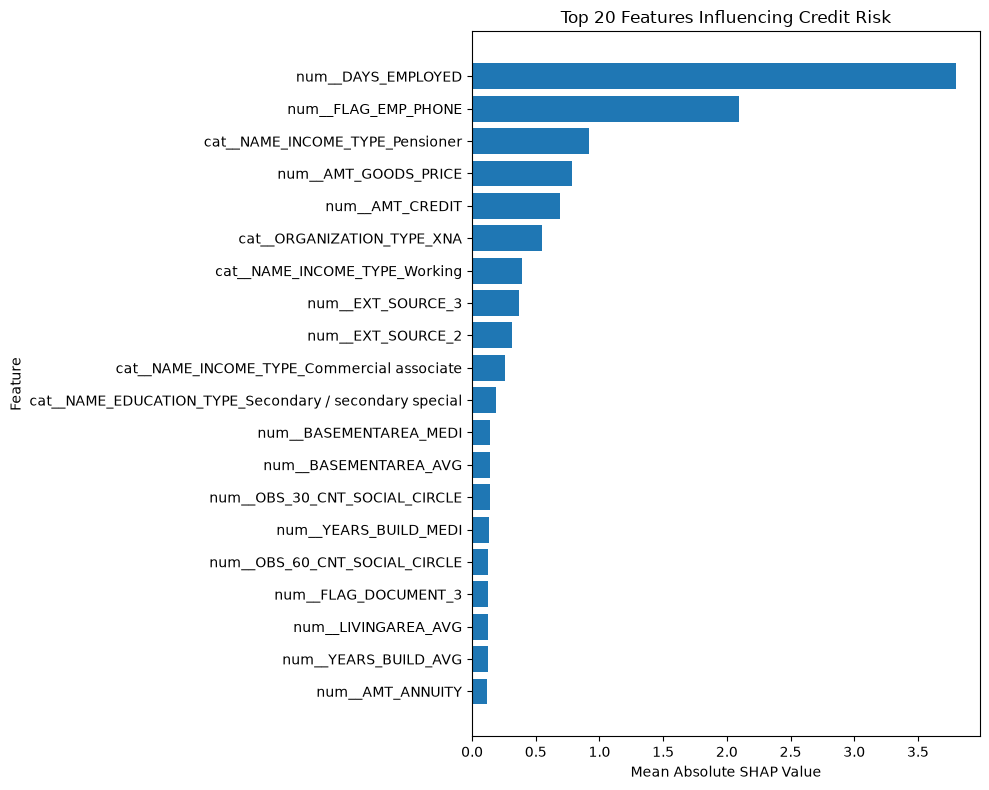

In [65]:
top_features = shap_importance_df.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Top 20 Features Influencing Credit Risk")

plt.tight_layout()
plt.show()

In [66]:
single_applicant = X_test_processed[0:1]

single_shap = explainer.shap_values(
    single_applicant
)

print("Individual SHAP explanation generated!")

Individual SHAP explanation generated!


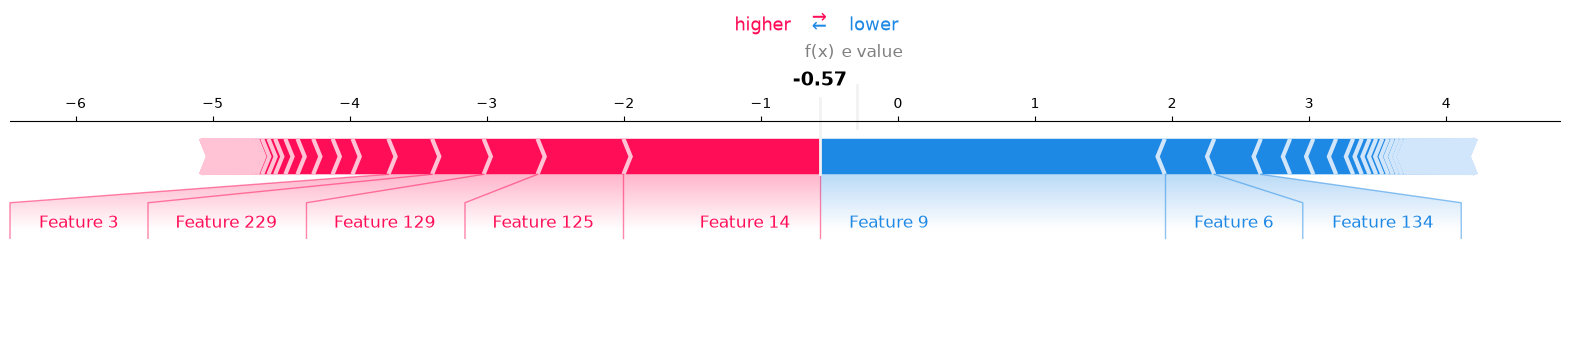

In [67]:
shap.force_plot(
    explainer.expected_value,
    single_shap,
    matplotlib=True
)

In [68]:
single_shap_values = single_shap[0]

individual_explanation = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": single_shap_values
})

individual_explanation["Absolute_SHAP"] = (
    individual_explanation["SHAP_Value"].abs()
)

individual_explanation = individual_explanation.sort_values(
    "Absolute_SHAP",
    ascending=False
)

print(
    individual_explanation.head(10)
)

                                               Feature  SHAP_Value  \
9                                   num__DAYS_EMPLOYED   -2.517017   
14                                 num__FLAG_EMP_PHONE    1.431960   
125                    cat__NAME_INCOME_TYPE_Pensioner    0.627022   
129                      cat__NAME_INCOME_TYPE_Working    0.393062   
229                         cat__ORGANIZATION_TYPE_XNA    0.376229   
6                                 num__AMT_GOODS_PRICE   -0.361033   
134  cat__NAME_EDUCATION_TYPE_Secondary / secondary...   -0.339965   
3                                      num__AMT_CREDIT    0.318845   
31                                   num__EXT_SOURCE_3    0.261595   
81                                num__FLAG_DOCUMENT_3   -0.213230   

     Absolute_SHAP  
9         2.517017  
14        1.431960  
125       0.627022  
129       0.393062  
229       0.376229  
6         0.361033  
134       0.339965  
3         0.318845  
31        0.261595  
81        0.213230 

In [69]:
risk_factors = individual_explanation[
    individual_explanation["SHAP_Value"] > 0
].head(5)

print("Top Risk-Increasing Factors:")
print(risk_factors)

Top Risk-Increasing Factors:
                             Feature  SHAP_Value  Absolute_SHAP
14               num__FLAG_EMP_PHONE    1.431960       1.431960
125  cat__NAME_INCOME_TYPE_Pensioner    0.627022       0.627022
129    cat__NAME_INCOME_TYPE_Working    0.393062       0.393062
229       cat__ORGANIZATION_TYPE_XNA    0.376229       0.376229
3                    num__AMT_CREDIT    0.318845       0.318845


In [70]:
protective_factors = individual_explanation[
    individual_explanation["SHAP_Value"] < 0
].head(5)

print("Top Risk-Reducing Factors:")
print(protective_factors)

Top Risk-Reducing Factors:
                                               Feature  SHAP_Value  \
9                                   num__DAYS_EMPLOYED   -2.517017   
6                                 num__AMT_GOODS_PRICE   -0.361033   
134  cat__NAME_EDUCATION_TYPE_Secondary / secondary...   -0.339965   
81                                num__FLAG_DOCUMENT_3   -0.213230   
30                                   num__EXT_SOURCE_2   -0.169336   

     Absolute_SHAP  
9         2.517017  
6         0.361033  
134       0.339965  
81        0.213230  
30        0.169336  


In [71]:
import ipywidgets as widgets

print("ipywidgets version:", widgets.__version__)

ipywidgets version: 8.1.9


In [72]:
def predict_credit_risk_demo(applicant_index):

    applicant = X_test_processed[applicant_index:applicant_index + 1]

    probability = logistic_model.predict_proba(applicant)[0, 1]

    score = 100 * (1 - probability)

    if score >= 70:
        band = "LOW"
    elif score >= 40:
        band = "MEDIUM"
    else:
        band = "HIGH"

    print("========== CREDIT RISK RESULT ==========")
    print("Applicant index      :", applicant_index)
    print("Default probability :", round(probability * 100, 2), "%")
    print("Credit risk score    :", round(score, 2))
    print("Credit risk band     :", band)

In [73]:
predict_credit_risk_demo(0)

========== CREDIT RISK RESULT ==========
Applicant index      : 0
Default probability : 36.11 %
Credit risk score    : 63.89
Credit risk band     : MEDIUM


In [74]:
applicant_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(X_test_processed) - 1,
    step=1,
    description="Applicant:"
)

In [75]:
output = widgets.Output()

In [76]:
def update_demo(change):

    with output:
        output.clear_output()

        predict_credit_risk_demo(
            applicant_slider.value
        )

In [77]:
applicant_slider.observe(
    update_demo,
    names="value"
)

In [78]:
display(
    applicant_slider,
    output
)

IntSlider(value=0, description='Applicant:', max=61502)

Output()

In [79]:
fraud_logistic_model
fraud_scaler
X_fraud_test_scaled
y_fraud_proba

array([4.99678997e-04, 1.52890638e-03, 5.23024098e-05, ...,
       1.57747759e-05, 7.05229910e-04, 1.23387471e-02], shape=(56962,))

In [80]:
def predict_fraud_demo(transaction_index):

    probability = y_fraud_proba[transaction_index]

    if probability >= 0.70:
        risk = "HIGH"
    elif probability >= 0.30:
        risk = "MEDIUM"
    else:
        risk = "LOW"

    print("========== FRAUD RISK RESULT ==========")
    print(
        "Transaction index  :",
        transaction_index
    )
    print(
        "Fraud probability  :",
        round(probability * 100, 2),
        "%"
    )
    print(
        "Fraud risk         :",
        risk
    )

In [81]:
predict_fraud_demo(0)

========== FRAUD RISK RESULT ==========
Transaction index  : 0
Fraud probability  : 0.05 %
Fraud risk         : LOW


In [82]:
def complete_demo(
    applicant_index,
    transaction_index
):

    # -------------------------
    # CREDIT RISK
    # -------------------------

    applicant = X_test_processed[
        applicant_index:applicant_index + 1
    ]

    credit_probability = (
        logistic_model
        .predict_proba(applicant)[0, 1]
    )

    credit_score = (
        100 * (1 - credit_probability)
    )

    if credit_score >= 70:
        credit_band = "LOW"

    elif credit_score >= 40:
        credit_band = "MEDIUM"

    else:
        credit_band = "HIGH"


    # -------------------------
    # FRAUD RISK
    # -------------------------

    fraud_probability = (
        y_fraud_proba[transaction_index]
    )

    if fraud_probability >= 0.70:
        fraud_band = "HIGH"

    elif fraud_probability >= 0.30:
        fraud_band = "MEDIUM"

    else:
        fraud_band = "LOW"


    # -------------------------
    # FINAL DECISION
    # -------------------------

    if fraud_probability >= best_fraud_threshold:

        decision = "FRAUD REVIEW REQUIRED"

    elif credit_band == "HIGH":

        decision = "HIGH RISK"

    elif credit_band == "MEDIUM":

        decision = "MANUAL REVIEW"

    else:

        decision = "LOW RISK"


    # -------------------------
    # DISPLAY
    # -------------------------

    print("=" * 45)
    print("      AI LOAN RISK DECISION SYSTEM")
    print("=" * 45)

    print("\nCREDIT RISK")
    print("-" * 25)
    print(
        "Default Probability:",
        round(credit_probability * 100, 2),
        "%"
    )
    print(
        "Credit Risk Score:",
        round(credit_score, 2)
    )
    print(
        "Credit Risk Band:",
        credit_band
    )

    print("\nFRAUD RISK")
    print("-" * 25)
    print(
        "Fraud Probability:",
        round(fraud_probability * 100, 2),
        "%"
    )
    print(
        "Fraud Risk Band:",
        fraud_band
    )

    print("\nFINAL DECISION")
    print("-" * 25)
    print(decision)

    print("=" * 45)

In [83]:
complete_demo(
    applicant_index=0,
    transaction_index=0
)

      AI LOAN RISK DECISION SYSTEM

CREDIT RISK
-------------------------
Default Probability: 36.11 %
Credit Risk Score: 63.89
Credit Risk Band: MEDIUM

FRAUD RISK
-------------------------
Fraud Probability: 0.05 %
Fraud Risk Band: LOW

FINAL DECISION
-------------------------
MANUAL REVIEW


In [84]:
applicant_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(X_test_processed) - 1,
    description="Applicant:"
)

transaction_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(y_fraud_proba) - 1,
    description="Transaction:"
)

In [85]:
combined_output = widgets.Output()

In [86]:
def update_complete_demo(change=None):

    with combined_output:

        combined_output.clear_output()

        complete_demo(
            applicant_slider.value,
            transaction_slider.value
        )

In [87]:
applicant_slider.observe(
    update_complete_demo,
    names="value"
)

transaction_slider.observe(
    update_complete_demo,
    names="value"
)

In [88]:
display(
    applicant_slider,
    transaction_slider,
    combined_output
)

IntSlider(value=0, description='Applicant:', max=61502)

IntSlider(value=0, description='Transaction:', max=56961)

Output()

In [89]:
print(credit_df.columns.tolist())

['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'NUM_INSTALMENT', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COM

In [90]:
gender_columns = [
    col for col in credit_df.columns
    if "gender" in col.lower()
    or "sex" in col.lower()
]

print(gender_columns)

['CODE_GENDER']


In [91]:
age_columns = [
    col for col in credit_df.columns
    if "age" in col.lower()
]

print(age_columns)

['OWN_CAR_AGE']


In [92]:
TARGET

NameError: name 'TARGET' is not defined

In [93]:
default_rate = credit_df["TARGET"].mean()

print(
    "Overall default rate:",
    round(default_rate * 100, 2),
    "%"
)

Overall default rate: 8.07 %


In [94]:
import joblib
import os

os.makedirs("models", exist_ok=True)

In [95]:
joblib.dump(
    logistic_model,
    "models/credit_logistic_model.pkl"
)

['models/credit_logistic_model.pkl']

In [96]:
joblib.dump(
    preprocessor,
    "models/credit_preprocessor.pkl"
)

['models/credit_preprocessor.pkl']

In [97]:
joblib.dump(
    fraud_scaler,
    "models/fraud_scaler.pkl"
)

['models/fraud_scaler.pkl']

In [98]:
joblib.dump(
    fraud_logistic_model,
    "models/fraud_logistic_model.pkl"
)

['models/fraud_logistic_model.pkl']

In [99]:
joblib.dump(
    best_fraud_threshold,
    "models/fraud_threshold.pkl"
)

['models/fraud_threshold.pkl']

In [100]:
print(os.listdir("models"))

['credit_logistic_model.pkl', 'credit_preprocessor.pkl', 'fraud_logistic_model.pkl', 'fraud_scaler.pkl', 'fraud_threshold.pkl']


In [101]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"],
    capture_output=True,
    text=True
)

with open("requirements.txt", "w") as f:
    f.write(result.stdout)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [102]:
import pandas as pd

final_credit_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.6900,
        0.6649,
        0.6902
    ],
    "Precision": [
        0.1616,
        0.1481,
        0.1541
    ],
    "Recall": [
        0.6785,
        0.6628,
        0.6318
    ],
    "F1 Score": [
        0.2611,
        0.2421,
        0.2477
    ],
    "ROC-AUC": [
        0.7487,
        0.7165,
        0.7207
    ],
    "PR-AUC": [
        0.2276,
        0.1921,
        0.1931
    ]
})

final_credit_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6900,0.1616,0.6785,0.2611,0.7487,0.2276
1,Decision Tree,0.6649,0.1481,0.6628,0.2421,0.7165,0.1921
2,Tuned Random Forest,0.6902,0.1541,0.6318,0.2477,0.7207,0.1931
